In [46]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import os
# import re

In [47]:
from analysis import small_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [53]:
df = pd.read_csv(os.path.join('..', 'experiments', 'keep_questionable', 'final_data.csv')) 

In [62]:
df.query('fish == "fishctrl1" and sample == 1')

,barcode,fish,sample,replicate,file,reads,proportion
7451,1D+38_NONE_NONE_5I+116+AGAGC_108D+142_108D+142...,fishctrl1,1,1,fishctrl1_s1_rep1,1711,0.666797
7452,40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NO...,fishctrl1,1,1,fishctrl1_s1_rep1,65,0.025331
7453,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fishctrl1,1,1,fishctrl1_s1_rep1,446,0.173811
7454,NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,fishctrl1,1,1,fishctrl1_s1_rep1,156,0.060795
7455,1D+38_NONE_NONE_5I+116+AGAGC_108D+142_108D+142...,fishctrl1,1,2,fishctrl1_s1_rep2,7805,0.474814
7456,40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NO...,fishctrl1,1,2,fishctrl1_s1_rep2,1036,0.063025
7457,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fishctrl1,1,2,fishctrl1_s1_rep2,675,0.041063
7458,NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,fishctrl1,1,2,fishctrl1_s1_rep2,5191,0.315793
7459,1D+38_NONE_NONE_5I+116+AGAGC_108D+142_108D+142...,fishctrl1,1,3,fishctrl1_s1_rep3,11955,0.478353
7460,40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NO...,fishctrl1,1,3,fishctrl1_s1_rep3,1155,0.046215


In [63]:
df.query('fish == "fishctrl1" and sample == 1')['barcode'].unique()

<StringArray>
['1D+38_NONE_NONE_5I+116+AGAGC_108D+142_108D+142_108D+142_108D+142_108D+142_NONE',
                     '40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NONE_NONE_NONE',
                  '84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_NONE_1D+253_NONE',
                              'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE']
Length: 4, dtype: str

In [66]:
df.query('barcode == "84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_NONE_1D+253_NONE"')

,barcode,fish,sample,replicate,file,reads,proportion
2289,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish18,4,2,fish18_s4_rep2,591,0.069800
2390,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish18,9,3,fish18_s9_rep3,190,0.033760
2705,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish21,1,1,fish21_s1_rep1,6250,0.293124
2710,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish21,1,2,fish21_s1_rep2,5961,0.285872
2715,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish21,1,3,fish21_s1_rep3,5559,0.264173
2722,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish21,2,1,fish21_s2_rep1,8145,0.186795
2729,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish21,2,2,fish21_s2_rep2,20528,0.184465
2736,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish21,2,3,fish21_s2_rep3,6592,0.184124
2743,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish21,4,1,fish21_s4_rep1,7655,0.288487
2750,84D+37_84D+37_84D+37_84D+37_2D+144_NONE_NONE_N...,fish21,4,2,fish21_s4_rep2,8785,0.282485


In [49]:
df = df[~df['fish'].str.contains('ctrl', case=False, na=False)]
df = df[df['sample'] == 1]

In [50]:
barcode_fish_appearances = (
    df.groupby("barcode")["fish"]
      .nunique()
      .rename("n_unique_fish")
)

def get_fish_barcodes(fish):
    """
    This function inputs a fish and returns a dataframe with the following columns:
    - barcode
    - reads
    - unique (boolean, True if the barcode does not appear in any other fish)
    """
    fish_barcodes = df[df['fish'] == fish].groupby('barcode', as_index = False).agg({'reads': 'sum'})
    fish_barcodes = fish_barcodes.join(
        barcode_fish_appearances.eq(1).rename("unique"),
        on="barcode"
    ).sort_values('reads', ascending = False)

    return fish_barcodes

In [51]:
def plot_pie(ax, fish):
    fish_barcodes = get_fish_barcodes(fish)

    out = (
        fish_barcodes.groupby('unique')['reads']
          .sum()
          .reindex([False, True], fill_value=0)
    )
    percent_true = out.loc[True] / out.sum()
    
    sizes = fish_barcodes["reads"]
    colors = fish_barcodes["unique"].map({True: "#36025c", False: "#D7C9F28C"})

    wedges, _ = ax.pie(
        sizes,
        labels=None,
        colors=colors,
        startangle=90,
        counterclock=False,
        wedgeprops={"linewidth": 0.5, "edgecolor": "white"},
        radius=1.0
    )

    fish_number = ''.join(filter(str.isdigit, fish_name))
    formatted_title = f"Fish {fish_number} ({100*percent_true:.0f}%)"

    ax.set_title(formatted_title, fontsize=7, pad=1, fontweight='bold')

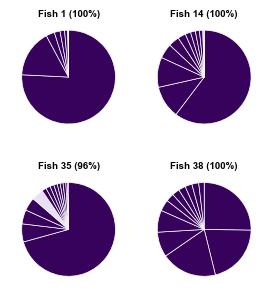

In [52]:
fishes = ['fish1', 'fish14', 'fish35', 'fish38']
fishes = sorted(fishes, key=lambda x: int(x.replace("fish", "")))

n_rows = 2
n_cols = 2
fig, axes = plt.subplots(2, 2, figsize = (3.5, 3.5))
plt.subplots_adjust(wspace=0, hspace=0.3)

ax = axes.ravel()
for i, fish_name in enumerate(fishes):
    plot_pie(ax[i], fish_name)
    
# for i in range(32, 36):
#     ax[i].set_visible(False)

# plt.tight_layout()
plt.savefig(os.path.join('images', 'pie.png'), dpi = 300)
plt.savefig(os.path.join('images', 'pie.svg'))

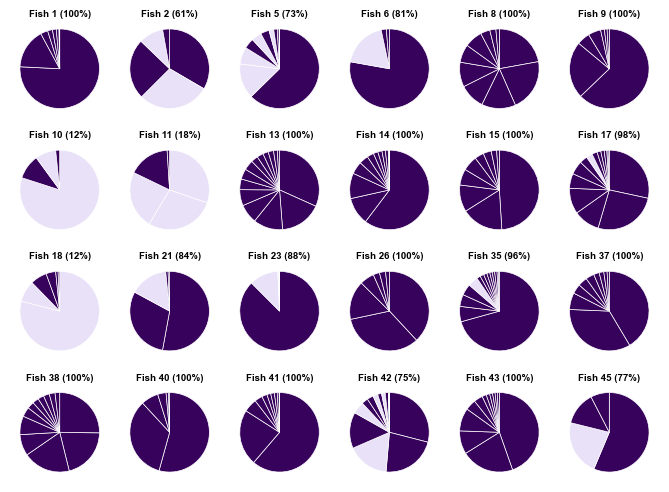

In [8]:
fishes = df['fish'].unique()
fishes = sorted(fishes, key=lambda x: int(x.replace("fish", "")))

n_rows = 4
n_cols = 6
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.7, 5))
# plt.subplots_adjust(wspace=0, hspace=0.3)

ax = axes.ravel()
for i, fish_name in enumerate(fishes):
    plot_pie(ax[i], fish_name)
    
# for i in range(32, 36):
#     ax[i].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join('images', 'allpie.png'), dpi = 300)
plt.savefig(os.path.join('images', 'allpie.svg'))

In [22]:
g = df.groupby('barcode').agg({'fish': 'nunique'})
g.head()

,fish
barcode,
107D+38_107D+38_107D+38_107D+38_107D+38_NONE_NONE_NONE_2D+251_NONE,1
107D+38_107D+38_107D+38_107D+38_107D+38_NONE_NONE_NONE_NONE_NONE,1
10D+29_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,1
12D+34_11D+65_NONE_NONE_NONE_87D+167_87D+167_87D+167_87D+167_NONE,1
12D+34_11D+65_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,1


In [25]:
v = g.value_counts()
v

fish
1       181
2         3
5         1
4         1
9         1
Name: count, dtype: int64

In [45]:
# Calculate % of barcodes that only appear in one fish.
# Do not include the unedited barcode.
percent_unique = v[1] / (v.sum() - 1)
print(f'{(1-percent_unique)*100:.1f}% of barcodes are shared.')

2.7% of barcodes are shared.


In [39]:
g.loc['NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE']

fish    9
Name: NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE, dtype: int64